# Catch Hallucinated Citations

Run every quote an AI answer cites through the source PDF, classify each citation, add up one number for the whole set, and write a shareable CSV and PDF report.

Companion notebook for the article [Catch Hallucinated Citations](https://pymupdf.io/blog/catch-hallucinated-citations) in the PyMuPDF grounding series. Tested with PyMuPDF 2.1.

In [1]:
%pip install -q pymupdf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Sample document
Creates the sample PDF used in the article. Replace the path with your own PDF to try it on real documents.

In [2]:
import pymupdf
doc = pymupdf.open()
sections = [
 ("Acme Corporation Annual Report 2025", None),
 ("1. Financial highlights", "Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. Operating margin improved to 18.4%, compared with 16.9% in the prior year. The company returned $350 million to shareholders through dividends and share repurchases."),
 ("2. Outlook", "Management expects revenue growth of 8% to 10% in fiscal 2026, with continued investment in cloud infrastructure and data centers in Europe and Asia. Capital expenditure is expected to reach $600 million."),
 ("3. Risk factors", "The company depends on a small number of large customers. In fiscal 2025, the three largest customers accounted for 31% of net revenue. The loss of any of these customers could materially affect results."),
 ("4. Supply chain", "Supply chain disruptions in 2024 delayed shipments of hardware appliances by up to six weeks. These delays did not recur in 2025, and inventory levels returned to normal by the second quarter."),
]
page = doc.new_page(); y = 72
for i,(h,body) in enumerate(sections):
    if i == 3:
        page = doc.new_page(); y = 72
    size = 18 if i == 0 else 14
    page.insert_text((72, y+size), h, fontsize=size, fontname="hebo"); y += size + 14
    if body:
        r = pymupdf.Rect(72, y, 400, y+200)
        rc = page.insert_textbox(r, body, fontsize=11, fontname="helv")
        y += 200 - rc + 18
doc.save("acme_report.pdf")


# A second sample document: an invoice
import pymupdf
doc = pymupdf.open(); p = doc.new_page()
B, R = "hebo", "helv"
p.insert_text((72, 80), "Northwind Cloud Services Ltd.", fontsize=16, fontname=B)
p.insert_text((72, 98), "12 Harbour Street, London EC2A 4BX, United Kingdom", fontsize=9, fontname=R)
p.insert_text((400, 80), "INVOICE", fontsize=20, fontname=B)
labels = [("Invoice number:", "INV-2026-0417"), ("Invoice date:", "October 15, 2026"),
          ("Due date:", "November 14, 2026"), ("PO number:", "PO-88213")]
y = 120
for l, v in labels:
    p.insert_text((360, y), l, fontsize=10, fontname=B); p.insert_text((450, y), v, fontsize=10, fontname=R); y += 16
p.insert_text((72, 140), "Bill to:", fontsize=10, fontname=B)
p.insert_text((72, 156), "Acme Corporation", fontsize=10, fontname=R)
p.insert_text((72, 170), "500 Market Street, San Francisco, CA 94105", fontsize=10, fontname=R)
rows = [["Description", "Qty", "Unit price", "Amount"],
        ["Cloud hosting, October 2026", "1", "8,400.00", "8,400.00"],
        ["Managed database service", "3", "1,250.00", "3,750.00"],
        ["Premium support plan", "1", "1,200.00", "1,200.00"]]
x = [72, 312, 362, 442, 522]; y0, h = 210, 20
for i, row in enumerate(rows):
    for j, cell in enumerate(row):
        r = pymupdf.Rect(x[j], y0 + i*h, x[j+1], y0 + (i+1)*h)
        p.draw_rect(r, color=(0.6, 0.6, 0.6), width=0.5)
        font = B if i == 0 else R
        w = pymupdf.get_text_length(cell, fontname=font, fontsize=9)
        xpos = r.x0 + 4 if j == 0 else r.x1 - 4 - w
        p.insert_text((xpos, r.y1 - 6), cell, fontsize=9, fontname=font)
tot = [("Subtotal", "13,350.00"), ("VAT (20%)", "2,670.00"), ("Total due (GBP)", "16,020.00")]
y = 310
for l, v in tot:
    font = B if l.startswith("Total") else R
    p.insert_text((362, y), l, fontsize=10, fontname=font)
    w = pymupdf.get_text_length(v, fontname=font, fontsize=10)
    p.insert_text((518 - w, y), v, fontsize=10, fontname=font); y += 18
p.insert_text((72, 400), "Payment terms: 30 days. Bank: Barclays, sort code 20-00-00, account 43210987.", fontsize=9, fontname=R)
doc.save("invoice.pdf")


# The answers to check, with their citations. The last cites a document that was never provided.
import json
answers = [
  {
    "id": "q1",
    "question": "How did Acme perform in 2025?",
    "answer": "Revenue grew 12% to $4.1 billion and operating margin rose to 18.4%.",
    "citations": [
      {
        "doc": "acme_report.pdf",
        "page": 1,
        "quote": "Net revenue increased 12% to $4.1 billion"
      },
      {
        "doc": "acme_report.pdf",
        "page": 1,
        "quote": "Operating margin improved to 18.4%"
      }
    ]
  },
  {
    "id": "q2",
    "question": "What does Acme expect for 2026?",
    "answer": "Acme expects 8% to 12% growth, capital expenditure of $600 million and a new data center in South America.",
    "citations": [
      {
        "doc": "acme_report.pdf",
        "page": 1,
        "quote": "Management expects revenue growth of 8% to 12% in fiscal 2026"
      },
      {
        "doc": "acme_report.pdf",
        "page": 1,
        "quote": "Capital expenditure is expected to reach $600 million"
      },
      {
        "doc": "acme_report.pdf",
        "page": 1,
        "quote": "The company plans to open a data center in South America in 2026"
      }
    ]
  },
  {
    "id": "q3",
    "question": "What are the main risks?",
    "answer": "Customer concentration: the three largest customers make up 31% of revenue. Supply chain delays in 2024 have been resolved.",
    "citations": [
      {
        "doc": "acme_report.pdf",
        "page": 1,
        "quote": "the three largest customers accounted for 31% of net revenue"
      },
      {
        "doc": "acme_report.pdf",
        "page": 2,
        "quote": "Supply chain disruptions in 2024 delayed shipments of hardware appliances by up to six weeks"
      },
      {
        "doc": "acme_report.pdf",
        "page": 2,
        "quote": "Inventory returned to normal levels by the second quarter"
      }
    ]
  },
  {
    "id": "q4",
    "question": "What does Acme owe Northwind?",
    "answer": "GBP 16,020.00, due on November 14, 2026, with 45-day payment terms.",
    "citations": [
      {
        "doc": "invoice.pdf",
        "page": 1,
        "quote": "Total due (GBP) 16,020.00"
      },
      {
        "doc": "invoice.pdf",
        "page": 1,
        "quote": "Due date: November 14, 2026"
      },
      {
        "doc": "invoice.pdf",
        "page": 1,
        "quote": "Payment terms: 45 days"
      }
    ]
  },
  {
    "id": "q5",
    "question": "Who audits Acme?",
    "answer": "Acme is audited by Baker & Lowe LLP.",
    "citations": [
      {
        "doc": "acme_10k.pdf",
        "page": 54,
        "quote": "Baker & Lowe LLP has served as the company's auditor since 2011"
      }
    ]
  }
]
json.dump(answers, open("answers.json", "w"), indent=2)

## Grounding helpers
`locate()` comes from the first article in the series, [Cite Claude's Answers at the Exact Spot in the PDF](https://pymupdf.io/blog/cite-claude-answers-at-the-exact-spot-in-the-pdf). It is also part of [the PyMuPDF grounding skill](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill).

In [3]:
import re
import pymupdf


def locate(page, cited_text):
    """Return the quads of cited_text on a page, or [] if not found."""
    text = " ".join(cited_text.split())          # collapse whitespace and line breaks
    quads = page.search_for(text, quads=True)    # case-insensitive, joins hyphenated words
    if quads:
        return quads
    return _locate_by_words(page, text)          # fallback for small differences


def _norm(word):
    return re.sub(r"[^\w%$.]", "", word).lower().rstrip(".")


def _locate_by_words(page, text):
    """Match the quote word by word, ignoring punctuation, case and hyphenation."""
    target = [_norm(w) for w in text.split() if _norm(w)]
    words = page.get_text("words", flags=pymupdf.TEXT_DEHYPHENATE)
    tokens = [(_norm(w[4]), pymupdf.Rect(w[:4])) for w in words]
    tokens = [t for t in tokens if t[0]]
    n = len(target)
    for i in range(len(tokens) - n + 1):
        if all(tokens[i + k][0] == target[k] for k in range(n)):
            return [r.quad for _, r in tokens[i:i + n]]
    return []

## Step 1: Collect the citations

All the check needs is, for each citation, the document, the page and the quoted text. Store the answers you want to evaluate in a simple JSON file. Two of the sample answers:

The q2 answer adds a growth figure the report does not contain and a data center it never mentions. The q5 answer cites a document that was never provided.

Citations from Claude's Citations API convert directly:

In [4]:
def from_claude(response, names):
    """Claude page_location citations as {doc, page, quote}; names lists the PDFs in the order sent."""
    return [{"doc": names[c.document_index], "page": c.start_page_number, "quote": c.cited_text}
            for b in response.content if b.type == "text"
            for c in (b.citations or []) if c.type == "page_location"]

Claude extracts `cited_text` from the document itself, so these citations should almost always verify; running them through the check confirms the page and gives you coordinates. The check matters most where the model writes the quote itself: prompt-based citations from any model, agent outputs, and drafted documents such as briefs and reports.

## Step 2: Check each citation

A citation is **verified** when the quote is found on the page it cites. If the quote is in the document but on another page, it is a **wrong page**: the text is real, the pointer is not. Quotes are located with the `locate()` function from the first article in this series, which ignores line breaks, hyphenation, case and punctuation.

In [5]:
import csv
import difflib
import json
import os
import re

import pymupdf

def check_citation(docs, cit, close=0.7):
    """Classify one citation: verified, wrong page, close match, not found or missing document."""
    row = dict(cit)
    doc = docs.get(cit["doc"])
    if doc is None:
        return {**row, "status": "missing document"}
    cited = doc[cit["page"] - 1] if 1 <= cit["page"] <= doc.page_count else None
    if cited is not None and locate(cited, cit["quote"]):
        return {**row, "status": "verified", "found_page": cit["page"]}
    for page in doc:
        if page is not cited and locate(page, cit["quote"]):
            return {**row, "status": "wrong page", "found_page": page.number + 1}
    ratio, pno, passage = closest_passage(doc, cit["quote"])
    row.update(similarity=round(ratio, 2), closest=passage, closest_page=pno)
    if ratio >= close:
        return {**row, "status": "close match", "differences": differences(cit["quote"], passage)}
    return {**row, "status": "not found"}

## Step 3: Tell an altered quote from an invented one

A quote that is not in the document is not always invented. Often the model kept the sentence and changed a number, or reworded it slightly. Those cases need a different response from a quote that has nothing to do with the document, so for every quote that was not found we look for the most similar passage and list the words that differ. A passage that is at least 70% similar is reported as a **close match**; anything less is **not found**. Neither counts as verified.

In [6]:
def words(text):
    """Lowercase words without punctuation, for comparing quotes with page text."""
    return [w for w in (re.sub(r"[^\w%$.]", "", t).lower().rstrip(".") for t in text.split()) if w]

def closest_passage(doc, quote):
    """The passage in doc most similar to quote: (similarity 0-1, page number, text)."""
    target = words(quote)
    best = (0.0, None, "")
    for page in doc:
        page_words = page.get_text("words", flags=pymupdf.TEXT_DEHYPHENATE)
        tokens = [w[4] for w in page_words]
        n = len(target)
        for i in range(max(1, len(tokens) - n + 1)):
            window = tokens[i:i + n]
            ratio = difflib.SequenceMatcher(None, target, words(" ".join(window))).ratio()
            if ratio > best[0]:
                best = (ratio, page.number + 1, " ".join(window))
    return best

def differences(quote, passage):
    """Words that differ between a quote and a passage, e.g. ['12% -> 10%']."""
    a, b = words(quote), words(passage)
    if sorted(a) == sorted(b):
        return ["same words, different order"]
    out = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b).get_opcodes():
        if op != "equal":
            out.append(f'{" ".join(a[i1:i2]) or "(nothing)"} -> {" ".join(b[j1:j2]) or "(nothing)"}')
    return out

## Step 4: Run the evaluation

In [7]:
answers = json.load(open("answers.json"))
names = {c["doc"] for a in answers for c in a["citations"]}
docs = {name: pymupdf.open(name) for name in names if os.path.exists(name)}
rows = [{"id": a["id"], **check_citation(docs, c)} for a in answers for c in a["citations"]]
for r in rows:
    print(f'{r["id"]:3} {r["doc"]:16} p{r["page"]:<3} {r["status"]:16} {r.get("similarity","")} {r.get("differences","")}')

q1  acme_report.pdf  p1   verified          
q1  acme_report.pdf  p1   verified          
q2  acme_report.pdf  p1   close match      0.91 ['12% -> 10%']
q2  acme_report.pdf  p1   verified          
q2  acme_report.pdf  p1   not found        0.31 
q3  acme_report.pdf  p1   wrong page        
q3  acme_report.pdf  p2   verified          
q3  acme_report.pdf  p2   close match      0.89 ['same words, different order']
q4  invoice.pdf      p1   verified          
q4  invoice.pdf      p1   verified          
q4  invoice.pdf      p1   close match      0.75 ['45 -> 30']
q5  acme_10k.pdf     p54  missing document  


Every planted error is caught, and the report says what kind it is. The changed growth range shows up as 12% where the report says 10%, and the payment terms as 45 where the invoice says 30. The inventory quote uses the document's words in a different order. The South America data center has no similar passage at all, and the auditor citation points to a document that was never provided.

Add up the statuses to get one number for the whole set:

In [8]:
STATUSES = ["verified", "wrong page", "close match", "not found", "missing document"]

def summarize(rows):
    """Count citations by status, with the share that could not be found in the source."""
    counts = {s: sum(r["status"] == s for r in rows) for s in STATUSES}
    unsupported = counts["close match"] + counts["not found"] + counts["missing document"]
    return {"citations": len(rows), **counts,
            "unsupported_rate": round(unsupported / len(rows), 3) if rows else 0.0}

In [9]:
print(json.dumps(summarize(rows), indent=2))

{
  "citations": 12,
  "verified": 6,
  "wrong page": 1,
  "close match": 3,
  "not found": 1,
  "missing document": 1,
  "unsupported_rate": 0.417
}


Five of twelve citations, 42%, are not supported by the cited documents. Wrong-page citations are counted separately: the quoted text exists, but the reader would not find it where the answer says.

## Step 5: Share the result

Write a CSV for spreadsheets and dashboards, and a PDF report for people. The report is built with PyMuPDF's `Story`, which lays out simple HTML on PDF pages, so no other tool is needed.

In [10]:
def write_csv(rows, path):
    """One line per citation, for spreadsheets and dashboards."""
    fields = ["id", "doc", "page", "quote", "status", "found_page",
              "similarity", "closest_page", "closest", "differences"]
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fields, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({**r, "differences": "; ".join(r.get("differences", []))})

COLORS = {"verified": "#1a7f37", "wrong page": "#9a6700", "close match": "#bc4c00",
          "not found": "#cf222e", "missing document": "#cf222e"}

def write_report(rows, summary, path, title="Citation check"):
    """A shareable PDF report: summary first, then one row per citation."""
    from html import escape
    unsupported = summary["citations"] - summary["verified"] - summary["wrong page"]
    html = [f"<h2>{escape(title)}</h2>",
            f"<p>{summary['citations']} citations checked. "
            f"<b>{unsupported} ({summary['unsupported_rate']:.0%}) were not found in the cited documents.</b></p>",
            "<p>" + ", ".join(f"{s}: {summary[s]}" for s in STATUSES) + "</p>",
            "<table><tr><th>ID</th><th>Cited</th><th>Quote</th><th>Result</th></tr>"]
    for r in rows:
        if r["status"] == "wrong page":
            detail = f"found on page {r['found_page']}"
        elif r["status"] == "close match":
            detail = (f"closest text, page {r['closest_page']}: &quot;{escape(r['closest'])}&quot; "
                      f"({escape('; '.join(r['differences']))})")
        elif r["status"] == "not found":
            detail = f"best match only {r['similarity']:.0%} similar"
        else:
            detail = ""
        html.append(f"<tr><td>{r['id']}</td><td>{escape(r['doc'])}, p. {r['page']}</td>"
                    f"<td>{escape(r['quote'])}</td>"
                    f"<td><b style='color:{COLORS[r['status']]}'>{r['status']}</b> {detail}</td></tr>")
    html.append("</table>")
    css = ("* {font-family: sans-serif; font-size: 9pt;} h2 {font-size: 14pt;}"
           "table {border-collapse: collapse;} th, td {border: 0.5px solid #999; padding: 3px; vertical-align: top;}"
           "th {background-color: #eee;}")
    story = pymupdf.Story(html="".join(html), user_css=css)
    writer = pymupdf.DocumentWriter(path)
    mediabox = pymupdf.paper_rect("a4")
    more = True
    while more:
        device = writer.begin_page(mediabox)
        more, _ = story.place(mediabox + (36, 36, -36, -36))
        story.draw(device)
        writer.end_page()
    writer.close()

summary = summarize(rows)
write_csv(rows, "citation_check.csv")
write_report(rows, summary, "citation_check.pdf")

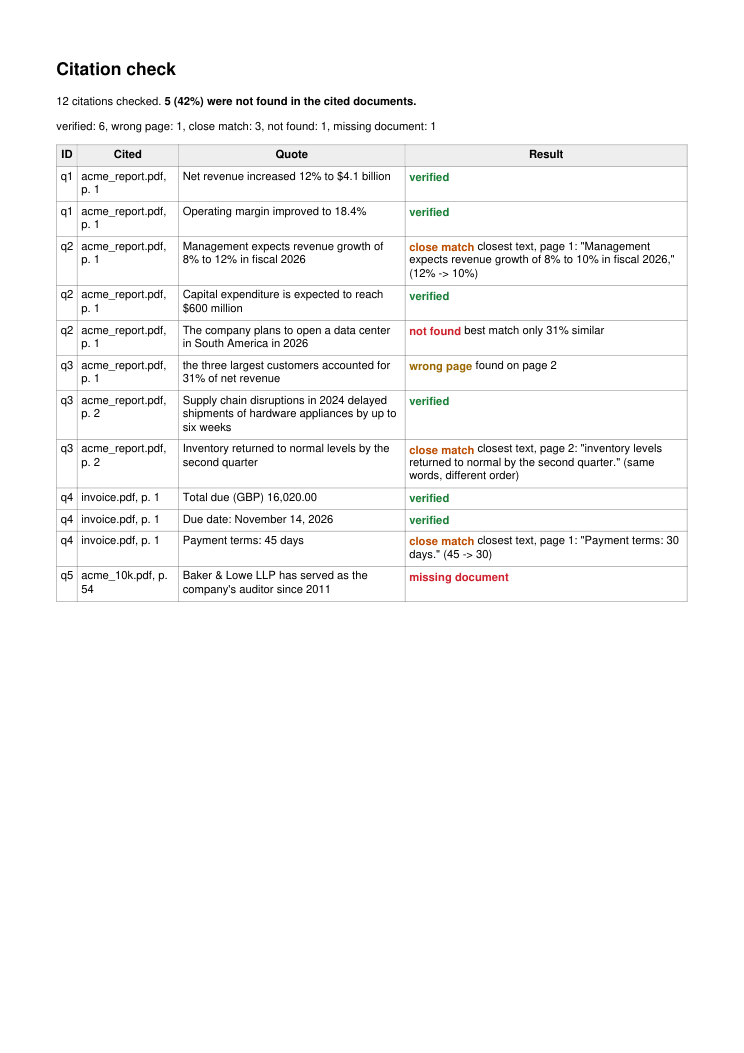

In [11]:
from IPython.display import Image, display
display(Image(pymupdf.open("citation_check.pdf")[0].get_pixmap(dpi=90).tobytes("png")))

## Use it as a test

Because the result is a single number, the check fits into evaluation and CI. Run the same question set against two models or two versions of a prompt and compare `unsupported_rate`, or fail a build when it rises above a limit:

In [12]:
if summary["unsupported_rate"] > 0.02:
    # In CI, raise SystemExit(...) here to fail the build
    print(f"{summary['unsupported_rate']:.0%} of citations were not found in their sources")

42% of citations were not found in their sources


## Limits to know
- This checks quotes. An answer that cites a page without quoting it, or paraphrases, cannot be checked by text matching; ask the model for exact quotes, as shown in the article on grounding answers from any model.
- A verified quote is in the document, but the claim built on it can still be wrong. Checking that a passage supports the claim needs a language model, and is out of scope here.
- The 70% threshold is a starting point. Very short quotes reach it with a single different word, so review close matches rather than treating them as correct.
- `closest_passage()` compares the quote with every passage of the same length in the document. It runs only for quotes that were not found, but on long documents limit it to the cited page and its neighbors.
- The PDF needs a text layer. Run OCR on scanned documents first, and see the OCR article in this series for flagging evidence that came from it.

## Next steps

- Read the full article: https://pymupdf.io/blog/catch-hallucinated-citations
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding